# 使用简单RNN完成IMDB电影评论情感分析


## 任务描述

本任务演示如何在IMDB数据集上使用RNN网络完成文本分类的任务。IMDB数据集包含对电影评论进行正向和负向标注的数据，共有25000条文本数据作为训练集，25000条文本数据作为测试集。

# 1. 环境配置

In [ ]:
import paddle
import numpy as np
import matplotlib.pyplot as plt
import paddle.nn as nn

print(paddle.__version__)  # 查看当前版本

# 判断CUDA是否可用，如果可用则使用GPU，否则使用CPU
device = paddle.set_device('gpu' if paddle.is_compiled_with_cuda() else 'cpu')
print("using {} device.".format(device))


In [ ]:
import datetime
import os

def printLog(name, ID):
    # 打印和
    print(': %s; : %s' % (name, ID))
    # 打印操作系统的用户名
    print("系统用户名:", os.getlogin())
    # 打印当前时间
    print('运行时间:', datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))

"""*********************************************************************
   【注意】运行前，请把下面代码中的“张三”改为自己的，123456改为自己的。
   *********************************************************************"""
printLog('张三', 123456)

# 2. 数据准备
[IMDB电影评论数据集](https://www.kaggle.com/c/word2vec-nlp-tutorial/data)是一份关于电影评论的经典二分类数据集．IMDB 按照评分的高低筛选出了积极评论和消极评论，如果评分 $ \geq 7 $，则认为是积极评论；如果评分 $ \le 4 $，则认为是消极评论．数据集包含训练集和测试集数据，数量各为 25000 条，每条数据都是一段用户关于某个电影的真实评价，以及观众对这个电影的情感倾向，其目录结构如下所示

      ├── train/
          ├── neg                 # 消极数据  
          ├── pos                 # 积极数据
          ├── unsup               # 无标签数据
      ├── test/
          ├── neg                 # 消极数据
          ├── pos                 # 积极数据

在test/neg目录中任选一条电影评论数据，内容如下：

> "Cover Girl" is a lacklustre WWII musical with absolutely nothing memorable about it, save for its signature song, "Long Ago and Far Away." 

RNN 模型不能直接处理文本数据，需要先将文本中单词转为向量表示，称为词向量（Word Embedding）．为了提高转换效率，通常会事先把文本的每个单词转换为数字 ID，再使用`paddle.nn.Embedding`进行向量转换．因此，需要准备一个词典（Vocabulary），将文本中的每个单词转换为它在词典中的序号 ID．同时还要设置一个特殊的词 [UNK]，表示未知词．在处理文本时，如果碰到不在词表的词，一律按 [UNK] 处理．

由于IMDB是NLP领域中常见的数据集，飞桨框架将其内置，路径为`paddle.text.datasets.Imdb`。通过`mode`参数可以控制训练集与测试集。

In [ ]:
print('loading dataset...')
train_dataset = paddle.text.datasets.Imdb(mode='train')
test_dataset = paddle.text.datasets.Imdb(mode='test')
print('loading finished')

构建了训练集与测试集后，可以通过`word_idx`获取数据集的词表。

In [ ]:
word_dict = train_dataset.word_idx  # 获取数据集的词表

# add a pad token to the dict for later padding the sequence 向词表构成的字典最后添加一个填充标记'<pad>'，以便稍后填充序列（长度补齐）
word_dict['<pad>'] = len(word_dict)
pad_id = word_dict['<pad>']  # 获取'<pad>'的id并打印输出
print("pad_id:", pad_id)  

for k in list(word_dict)[:5]:   # 输出词表的前5个词及其id
    print("{}:{}".format(k.decode('ASCII'), word_dict[k]))

print("...")

for k in list(word_dict)[-5:]:   # 输出词表的最后5个词及其id
    print("{}:{}".format(k if isinstance(k, str) else k.decode('ASCII'), word_dict[k]))

print("totally {} words".format(len(word_dict)))


## 2.1 参数设置
在这里设置词表大小、embedding大小、batch_size等参数。

In [ ]:
vocab_size = len(word_dict) + 1
print(vocab_size)

# MyRNN模型使用的参数：emb_size = 256，hidden_size = 256，seq_len = 200
# SimpleRNNModel模型使用的参数：emb_size = 16，hidden_size = 32，seq_len = 100
# 设置超参数
emb_size = 16   # 词嵌入向量的维度（word embedding大小，即每个词/token用一个emb_size维的向量表示）
hidden_size = 32  # Simple RNN中隐状态向量维度
seq_len = 100   # 序列长度，句子长度小于seq_len的用'<pad>'补齐，句子长度大于seq_len的截断
batch_size = 32
epochs = 20

classes = ['negative', 'positive']

# 生成句子列表，即将给定的一组ID转换成对应的字符串表示。
def ids_to_str(ids):  # ids: 一个包含多个ID的序列，这些ID是字典word_dict中的键。
    words = []
    for k in ids:
        w = list(word_dict)[k]  # 找到序号k对应的单词赋给w
        words.append(w if isinstance(w, str) else w.decode('utf-8'))   # 依次添加单词
    return " ".join(words)  # 返回一个字符串，其中每个ID被替换为word_dict中对应ID的值。

print("【1】训练集中第0条原始数据train_dataset[0]:", train_dataset[0])   # 包含2个array：第1个array（train_dataset[0][0]）为句子各个词的id，第2个array（train_dataset[0][1]）为label
print("【2】根据词表，train_dataset[0]对应的句子：", ids_to_str(train_dataset[0][0]))
print("【3】train_dataset[0]的标签：", classes[train_dataset[0][1][0]])

## 2.2 用padding的方式对齐数据
文本数据中，每一句话的长度都是不一样的，为了方便后续的神经网络的计算，通常使用padding的方式对齐数据。

需要引入下面两个功能：
1. 长度限制：需要将序列的长度控制在一定的范围内，避免部分数据过长影响整体训练效果
2. 长度补齐：神经网络模型通常需要同一批处理的数据的序列长度是相同的，然而在分批时通常会将不同长度序列放在同一批，因此需要对序列进行补齐处理．

对于长度限制，我们使用seq_len参数对于过长的文本进行截断．
对于长度补齐，我们先统计该批数据中序列的最大长度，并将短的序列填充一些没有特殊意义的占位符 [PAD]，将长度补齐到该批次的最大长度，这样便能使得同一批次的数据变得规整．比如给定两个句子：
- 句子1: This movie was craptacular.
- 句子2: I got stuck in traffic on the way to the theater.

将上面的两个句子补齐，变为：
- 句子1: This movie was craptacular [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
- 句子2: I got stuck in traffic on the way to the theater

In [ ]:
# 将数据处理成同样长度，句子长度小于seq_len的用'<pad>'补齐，句子长度大于seq_len的截断
def create_padded_dataset(dataset):
    padded_sents = []
    labels = []
    for batch_id, data in enumerate(dataset):
        sent, label = data[0], data[1]
        # 如果 seq_len 小于或等于 sent 的长度，[pad_id] * (seq_len - len(sent))实际上不会创建任何元素，因为 ( seq_len - len(sent) ) 的结果是非正数，乘以 [pad_id] 会得到一个空列表。
        padded_sent = np.concatenate([sent[:seq_len], [pad_id] * (seq_len - len(sent))]).astype('int32')
        padded_sents.append(padded_sent)
        labels.append(label)
    return np.array(padded_sents), np.array(labels)

# 对train、test数据进行实例化
train_sents, train_labels = create_padded_dataset(train_dataset)
test_sents, test_labels = create_padded_dataset(test_dataset)

# 查看数据大小及举例内容
print(train_sents.shape)
print(train_labels.shape)
print(test_sents.shape)
print(test_labels.shape)

for sent in train_sents[:3]:
    print(ids_to_str(sent))


## 2.3 用Dataset与DataLoader加载
将前面准备好的训练集与测试集用`Dataset`与`DataLoader`封装后，完成数据的加载。

In [ ]:
class IMDBDataset(paddle.io.Dataset):
    '''
    继承paddle.io.Dataset类进行封装数据
    '''
    def __init__(self, sents, labels):
        self.sents = sents
        self.labels = labels
    
    def __getitem__(self, index):
        data = self.sents[index]
        label = self.labels[index]

        return data, label

    def __len__(self):
        return len(self.sents)
    
train_dataset = IMDBDataset(train_sents, train_labels)
test_dataset = IMDBDataset(test_sents, test_labels)
print("【4】训练集中第0条原始数据截断和填充后的数据train_dataset[0]:", train_dataset[0])
print("【5】截断和填充后的句子长度len(train_dataset[0][0])是:", len(train_dataset[0][0]))

train_loader = paddle.io.DataLoader(train_dataset, return_list=True,
                                    shuffle=True, batch_size=batch_size, drop_last=True)
test_loader = paddle.io.DataLoader(test_dataset, return_list=True,
                                    shuffle=True, batch_size=batch_size, drop_last=True)


# 3. 模型配置
使用SRN模型进行IMDB电影评论情感分析任务的模型结构如下图所示。

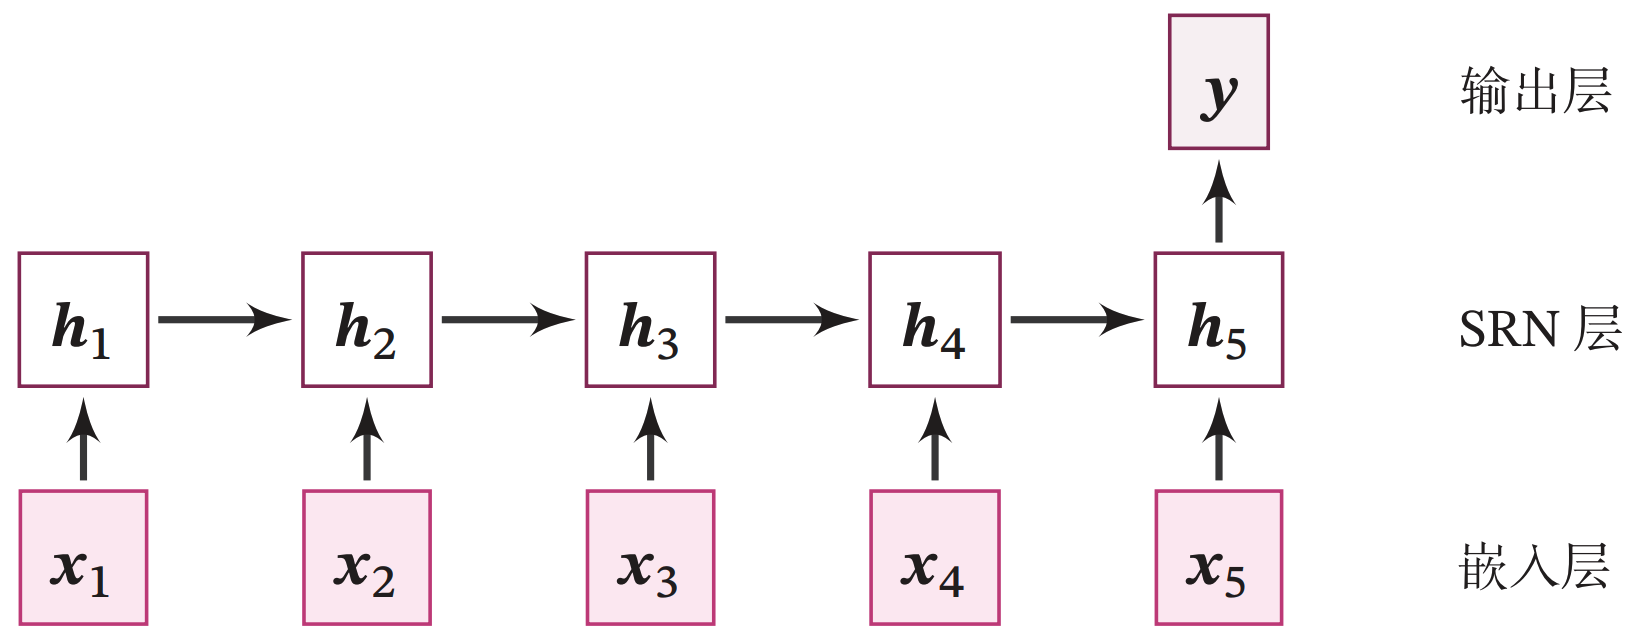

整个模型由以下几个部分组成：  
（1） 嵌入层：将输入的词（token）序列进行向量化，即将每个token映射为向量；  
（2） SRN 层：接收向量序列，更新循环单元，将最后时刻的隐状态作为整个序列的表示；  
（3） 输出层：一个线性层，输出分类的结果.  

## 3.1 嵌入层

本任务输入的样本是电影评论语句，为了更好地表示语句中的token，需要将token映射为一个嵌入（Embedding）向量。嵌入向量中的每个维度均能用来刻画该token本身的某种特性。

首先，我们构建一个嵌入矩阵（Embedding Matrix）$\boldsymbol{E}\in \mathbb{R}^{numEmb\times embDim}$，其中第$i$行对应第$i$个token的嵌入向量，每个嵌入向量的维度是$embDim$。如下图所示。
给定一个组数字序列$\boldsymbol{S} \in \mathbb{R}^{B\times L}$，其中$B$为批大小，$L$为序列长度，可以通过查嵌入矩阵表$\boldsymbol{E}$将其映射为嵌入表示$\boldsymbol{X}\in \mathbb{R}^{B\times L \times embDim}$。

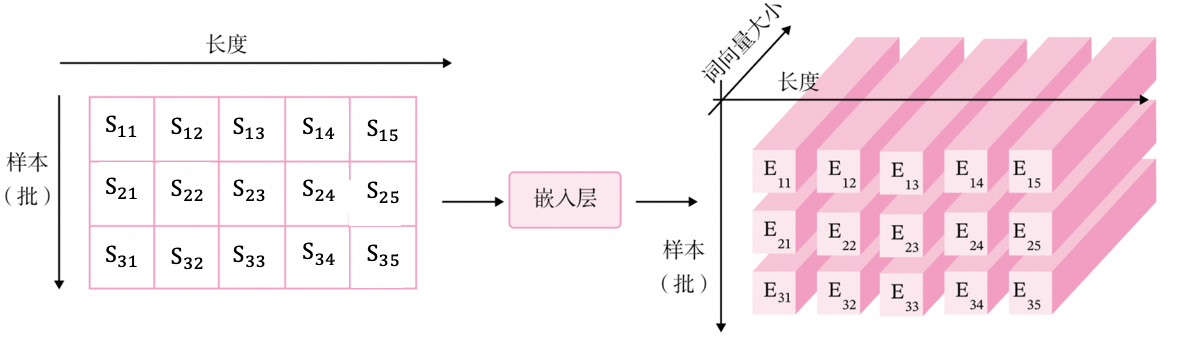

`paddle.nn.Embedding` 是 PaddlePaddle 深度学习框架中的一个层（Layer），它用于将正整数（索引）输入转换为具有固定大小的嵌入向量。`paddle.nn.Embedding` 层的主要参数包括：

* num_embeddings：嵌入向量的总数，通常等于词汇表的大小。
* embedding_dim：每个嵌入向量的维度。

__<span style="color: red;">Paddle的词嵌入请参考：</span>__ 
https://www.paddlepaddle.org.cn/documentation/docs/zh/api/paddle/nn/Embedding_cn.html#embedding

## 3.2 SRN层（paddle.nn.SimpleRNN）

`paddle.nn.SimpleRNN` 是 PaddlePaddle 深度学习框架中的一个循环神经网络（RNN）层，用于实现简单的循环神经网络结构。其主要特点有：
* SimpleRNN 由基本的循环单元组成，每个单元在每个时间步更新其状态，状态更新取决于当前输入和前一时间步的隐藏状态。
* 在 SimpleRNN 中，输入权重矩阵、隐藏状态权重矩阵和偏置项在所有时间步中都是共享的。
* SimpleRNN 适用于序列数据，可以处理任意长度的序列。

`paddle.nn.SimpleRNN` 的语法格式如下：

`paddle.nn.SimpleRNN(input_size, hidden_size, num_layers=1, activation='tanh', direction='forward', dropout=0.0, batch_first=False, dtype='float32', use_cudnn=True)`

`paddle.nn.SimpleRNN`层的主要参数包括：
* input_size：输入特征的维度。
* hidden_size：隐藏状态的维度。
* num_layers：堆叠的RNN层的数量。
* dropout：（可选）在堆叠层之间使用的dropout比率，用于正则化以防止过拟合。

__<span style="color: red;">`paddle.nn.SimpleRNN`官方文档请参考：</span>__ https://www.paddlepaddle.org.cn/documentation/docs/zh/api/paddle/nn/SimpleRNN_cn.html#simplernn



## 3.3 模型定义
下面定义了两种不同的RNN模型，都包含嵌入层、RNN层和线性层（上图中的输出层），最后通过softmax做分类。
* MyRNN的RNN层包含了2个隐藏层，将2个隐藏层的输出做了拼接，然后用Linear进行线性变换（情感分类输出只有积极、消极这两种类别，所以线性层的输出特征维度为2）并通过softmax做分类，同时，在隐藏层与线性层之间使用Dropout防止过拟合。
* SimpleRNNModel的RNN层包含了1个隐藏层。

In [ ]:
class MyRNN(paddle.nn.Layer):
    def __init__(self, vocab_size, emb_size, hidden_size):
        super(MyRNN, self).__init__()
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=emb_size)    # vocab_size：5149，emb_size：256
        self.rnn = nn.SimpleRNN(input_size=emb_size, hidden_size=hidden_size, num_layers=2, direction='forward',dropout=0.5)  # num_layers=2，有2个隐藏层
        self.linear = nn.Linear(in_features=hidden_size*2, out_features=2)   # 两个隐藏层的输出做了拼接，维度x2
        self.dropout = nn.Dropout(0.5)
        self.softmax = paddle.nn.Softmax()
    
    def forward(self, inputs):
        emb = self.dropout(self.embedding(inputs))
        output, hidden = self.rnn(emb)
        hidden = paddle.concat((hidden[-2,:,:], hidden[-1,:,:]), axis = 1)  # 两个隐藏层的输出做了拼接，维度x2
        hidden = self.dropout(hidden)
        x = self.linear(hidden)
        x = self.softmax(x)
        return x 

class SimpleRNNModel(paddle.nn.Layer):
    def __init__(self, vocab_size, emb_size, hidden_size):
        super(SimpleRNNModel, self).__init__()
        self.emb = paddle.nn.Embedding(num_embeddings=vocab_size, embedding_dim=emb_size)
        self.simple_rnn = paddle.nn.SimpleRNN(input_size=emb_size, hidden_size=hidden_size)  # 默认隐藏层为1层
        self.fc = paddle.nn.Linear(in_features=hidden_size, out_features=2)
        self.softmax = paddle.nn.Softmax()

    def forward(self, x):
        x = self.emb(x)
        # SimpleRNN分别返回所有时刻状态和最后时刻状态，这里只使用最后时刻状态
        _, x = self.simple_rnn(x)
        # 去掉第0维，这么处理与PaddlePaddle的SimpleRNN层返回格式有关
        x = paddle.squeeze(x, axis=0)
        x = self.fc(x)
        x = self.softmax(x)
        return x

# model = MyRNN(vocab_size, emb_size, hidden_size)  # 前面参数定义部分定义了emb_size、hidden_size
model = SimpleRNNModel(vocab_size, emb_size, hidden_size)
# 查看模型结构信息
paddle.summary(model, input_size=(None, seq_len), dtypes='int64')


# 4. 模型训练

使用PaddlePaddle低阶API训练模型，定义train函数，遍历epochs次训练样本，在每个epoch的每个batch内，依次执行前向计算、计算损失、后向传播、梯度更新，并且每个epoch遍历结束后评估测试集准确率。

In [ ]:
# 可视化定义   
def draw_process(title, color, xdata, ydata, xlabel, ylabel):
    plt.title(title, fontsize=24)
    plt.xlabel(xlabel, fontsize=20)
    plt.ylabel(ylabel, fontsize=20)
    plt.plot(xdata, ydata, color=color, label=ylabel)
    plt.legend()
    plt.grid()
    plt.show()


# 对模型进行封装
def train(model, epochs):
    model.train()
    opt = paddle.optimizer.Adam(learning_rate=0.001, parameters=model.parameters())
    steps = 0
    Iters, total_loss, total_acc = [], [], []
    # 定义验证集上的最佳准确率变量，初始设置为0.0
    best_acc = 0.0
    # 记录每一轮在验证集上的准确率和损失
    val_acc, val_loss = [], []

    for epoch in range(epochs):
        model.train()  # 训练模式
        for batch_id, data in enumerate(train_loader):
            steps += 1
            sent = data[0]  # data[0]是句子
            label = data[1]  # data[1]是标签
            label = paddle.cast(label, 'int64')
            
            logits = model(sent)
            loss = paddle.nn.functional.cross_entropy(logits, label)
            acc = paddle.metric.accuracy(logits, label)

            if batch_id % 500 == 0:  # 500个epoch输出一次结果
                Iters.append(steps)
                total_loss.append(loss.numpy()[0])
                total_acc.append(acc.numpy()[0])

                print("epoch: {}, batch_id: {}, loss is: {}".format(epoch, batch_id, loss.numpy()))
            
            loss.backward()
            opt.step()
            opt.clear_grad()

        # 每轮在验证集上评估模型
        model.eval()   # 验证模式
        accuracies = []
        losses = []
        
        for batch_id, data in enumerate(test_loader):
            sent = data[0]
            label = data[1]
            label = paddle.cast(label, 'int64')

            logits = model(sent)
            loss = paddle.nn.functional.cross_entropy(logits, label)
            acc = paddle.metric.accuracy(logits, label)
            
            accuracies.append(acc.numpy())
            losses.append(loss.numpy())
        
        avg_acc, avg_loss = np.mean(accuracies), np.mean(losses)
        val_acc.append(avg_acc)
        val_loss.append(avg_loss)
        
        print("[validation] accuracy: {}, loss: {}".format(avg_acc, avg_loss))
        
        # 如果当前模型在验证集上的准确率是最佳，则保存模型
        if avg_acc > best_acc:
            best_acc = avg_acc
            # 保存模型
            paddle.save(model.state_dict(), "best_model.pdparams")
            print("save best_model")
             
    
    print("【6】验证集上最大准确率：", max(val_acc))
    # 可视化查看，训练集损失和准确率变化曲线
    draw_process(title="training loss", color='#e4007f', xdata=Iters, ydata=total_loss, xlabel="iter", ylabel="training loss")
    draw_process(title="training acc", color='#e4007f', xdata=Iters, ydata=total_acc, xlabel="iter", ylabel="training acc")
    # 可视化查看，验证集准确率变化曲线
    epoch = list(range(epochs))  # plot函数中xdata和ydata的维度要相同
    draw_process(title="val acc", color="red", xdata=epoch, ydata=val_acc, xlabel="epochs", ylabel="val acc")


train(model, epochs = epochs)

"""*********************************************************************
   【注意】运行前，请把下面代码中的“张三”改为自己的，123456改为自己的。
   *********************************************************************"""
printLog('张三', 123456)

# 5. 模型评估
加载前面训练过程中保存的最好的模型`best_model.pdparams`在测试集上进行评估。

In [ ]:
model_state_dict = paddle.load('best_model.pdparams')  # 导入训练中的最佳模型
# model = MyRNN(vocab_size, emb_size, hidden_size)
model = SimpleRNNModel(vocab_size, emb_size, hidden_size)
model.set_state_dict(model_state_dict) 
model.eval()
accuracies = []
losses = []

for batch_id, data in enumerate(test_loader):
    sent = data[0]
    label = data[1]
    label = paddle.cast(label, 'int64')

    logits = model(sent)
    loss = paddle.nn.functional.cross_entropy(logits, label)
    acc = paddle.metric.accuracy(logits, label)
    
    accuracies.append(acc.numpy())
    losses.append(loss.numpy())

avg_acc, avg_loss = np.mean(accuracies), np.mean(losses)
print("[validation] accuracy: {}, loss: {}".format(avg_acc, avg_loss))

"""*********************************************************************
   【注意】运行前，请把下面代码中的“张三”改为自己的，123456改为自己的。
   *********************************************************************"""
printLog('张三', 123456)

# 6. 模型预测

In [ ]:

label_map = {0: "negative", 1: "positive"}

# 导入模型
model_state_dict = paddle.load('best_model.pdparams')
# model = MyRNN(vocab_size, emb_size, hidden_size)
model = SimpleRNNModel(vocab_size, emb_size, hidden_size)
model.set_state_dict(model_state_dict) 
model.eval()

for batch_id, data in enumerate(test_loader):
    sent = data[0]
    results = model(sent)

    predictions = []
    for probs in results:
        # 映射分类label
        idx = np.argmax(probs)   
        labels = label_map[idx]
        predictions.append(labels)
    
    for i, pre in enumerate(predictions):
        print(' 数据: {} \n 情感: {}'.format(ids_to_str(sent[i]), pre))
#         break
    break   # 只输出test_loader中第1个batch的数据和预测类别
